# Notebook 08: Margens de Segurança Prudenciais, Perda Assimétrica e Modelagem Híbrida (IA + Especialista)
**Projeto:** Artefato Técnico de Previsão de Demanda de Refeições — IFSP Campus Itaquaquecetuba  
**Mestrado Profissional em Educação Profissional e Tecnológica (ProfEPT / Gestão Pública)**  
**Autor:** Antigravity & Pesquisador  
**Data:** Outubro de 2026  

---

## 1. Contexto e Motivação Científica

Em serviços de alimentação escolar pública, errar a demanda não possui consequências simétricas:
- **Potencial de Sobra ($C_o$ — *Overage Cost*):** Desperdício orçamentário e descarte de alimento perecível.
- **Potencial de Falta ($C_u$ — *Underage Cost*):** Gravíssimo na escola pública — afeta a segurança alimentar, a capacidade cognitiva na aula e a dignidade do estudante.

Este notebook implementa e avalia as **abordagens consagradas na literatura científica** de Pesquisa Operacional e Machine Learning (documentadas em `docs/referencias_margens_seguranca_e_modelagem.md`):
1. **O Modelo do *Newsvendor* com Perda Assimétrica:** Fração crítica de atendimento ($SL^* = \frac{C_u}{C_u + C_o}$).
2. **Predição Conformal Não-Paramétrica (*Conformal Prediction*):** Margens com garantia estatística finite-sample livre de distribuição teórica ($Q^* = \hat{y} + \text{Quantil}_{1-\alpha}$).
3. **Modelo Híbrido Colaborativo (*Collaborative Forecasting*):** Combinação linear ponderada da IA com a nutricionista ($\hat{y}_{hibrido} = \alpha \cdot \hat{y}_{IA} + (1-\alpha) \cdot \text{Reserva}$).
4. **Simulação de Monte Carlo / Incerteza Estocástica:** Bandas probabilísticas de risco para apoio à tomada de decisão da gestão.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats

# Configuração estética padronizada de 300 DPI
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 14

FIG_DIR = "../reports/figuras/06_margens_seguranca_e_modelo_hibrido"
os.makedirs(FIG_DIR, exist_ok=True)
print(f"[OK] Diretório de figuras pronto: {FIG_DIR}")


[OK] Diretório de figuras pronto: ../reports/figuras/06_margens_seguranca_e_modelo_hibrido


## 2. Carga dos Resultados Consolidados do Walk-Forward de 2026
Carregamos as predições detalhadas de 2026 no **Horizonte $t+1$ (Semana Seguinte — Perecíveis)** para comparar o melhor modelo de IA (**Ridge no Cenário 3**) com o quantitativo planejado pela nutricionista e os consumos reais.


In [2]:
PRED_PATH = "../dados/gold/predicoes_detalhadas_walk_forward.parquet"
df_pred = pd.read_parquet(PRED_PATH)

# Filtrar horizonte t+1
df_t1 = df_pred[(df_pred["horizonte"] == "Semana_t1") & (df_pred["data_iso"] <= "2026-08-31")].copy()

# Obter predições do melhor modelo (Ridge) e o quantitativo da nutricionista
df_ridge = df_t1[(df_t1["algoritmo"] == "Ridge") & (df_t1["cenario"] == "Cenario_3_Com_Nutricionista")][["data_iso", "sexta_corte", "y_real", "y_pred"]].rename(columns={"y_pred": "pred_ia"})
df_nutri = df_t1[df_t1["algoritmo"] == "Estimativa_Nutricionista_Pura"][["data_iso", "y_pred"]].rename(columns={"y_pred": "reserva_nutri"})

df_analise = pd.merge(df_ridge, df_nutri, on="data_iso", how="inner").sort_values("data_iso").reset_index(drop=True)
df_analise["data_dt"] = pd.to_datetime(df_analise["data_iso"])

print(f"Total de dias letivos de teste em 2026 analisados: {len(df_analise)}")
print(df_analise.head())


Total de dias letivos de teste em 2026 analisados: 100
     data_iso sexta_corte  y_real     pred_ia  reserva_nutri    data_dt
0  2026-02-09  2026-02-06   200.0  170.680080          214.0 2026-02-09
1  2026-02-10  2026-02-06   151.0  170.738655          200.0 2026-02-10
2  2026-02-11  2026-02-06   147.0  155.812809          165.0 2026-02-11
3  2026-02-12  2026-02-06   157.0  131.836771          140.0 2026-02-12
4  2026-02-23  2026-02-20   216.0  185.724165          220.0 2026-02-23


## 3. Funções de Avaliação Operacional de Negócio
Definição rigorosa das métricas operacionais para a gestão escolar:
- **Potencial de Sobra ($S$):** $\sum \max(0, \hat{y} - y_{\text{real}})$ (refeições excedentes com risco de desperdício).
- **Potencial de Falta ($F$):** $\sum \max(0, y_{\text{real}} - \hat{y})$ (refeições em déficit com risco de desassistência ao aluno).
- **Taxa de Dias com Falta (%):** Porcentagem de dias letivos em que $y_{\text{real}} > \hat{y}$.


In [3]:
def avaliar_politica(y_true, y_pred):
    yt = np.array(y_true)
    yp = np.maximum(0, np.array(y_pred))
    
    sobra = np.sum(np.maximum(0, yp - yt))
    falta = np.sum(np.maximum(0, yt - yp))
    dias_falta = np.sum(yt > yp)
    pct_dias_falta = (dias_falta / len(yt)) * 100
    mae = mean_absolute_error(yt, yp)
    rmse = np.sqrt(mean_squared_error(yt, yp))
    r2 = r2_score(yt, yp)
    
    return {
        "sobra": int(sobra),
        "falta": int(falta),
        "total_desvio": int(sobra + falta),
        "dias_falta": int(dias_falta),
        "pct_dias_falta": round(pct_dias_falta, 1),
        "mae": round(mae, 2),
        "rmse": round(rmse, 2),
        "r2": round(r2, 3)
    }

# Linha de Base: IA Pura vs. Nutricionista Pura
res_ia_pura = avaliar_politica(df_analise["y_real"], df_analise["pred_ia"])
res_nutri_pura = avaliar_politica(df_analise["y_real"], df_analise["reserva_nutri"])

print("--- LINHA DE BASE: IA PURA ---")
print(res_ia_pura)
print("\n--- LINHA DE BASE: QUANTITATIVO DA NUTRICIONISTA ---")
print(res_nutri_pura)


--- LINHA DE BASE: IA PURA ---
{'sobra': 1369, 'falta': 735, 'total_desvio': 2105, 'dias_falta': 43, 'pct_dias_falta': np.float64(43.0), 'mae': 21.05, 'rmse': np.float64(30.49), 'r2': 0.548}

--- LINHA DE BASE: QUANTITATIVO DA NUTRICIONISTA ---
{'sobra': 1700, 'falta': 625, 'total_desvio': 2325, 'dias_falta': 40, 'pct_dias_falta': np.float64(40.0), 'mae': 23.25, 'rmse': np.float64(34.01), 'r2': 0.438}


## 4. Experimento 1: Fronteira Eficiente de Pareto do Modelo Híbrido
Simulamos o modelo híbrido linear convexo:
$$\hat{y}_{\text{híbrido}}(\alpha) = \alpha \cdot \hat{y}_{\text{IA}} + (1 - \alpha) \cdot \text{Quantitativo}_{\text{Nutricionista}}$$
Variamos $\alpha$ de $0{,}0$ (100% Nutricionista) a $1{,}0$ (100% IA) com passos de $0{,}025$ para mapear a **Curva de Trade-off Sobra vs. Falta**.


In [4]:
alphas = np.linspace(0.0, 1.0, 41)
resultados_pareto = []

for a in alphas:
    p_hib = a * df_analise["pred_ia"] + (1 - a) * df_analise["reserva_nutri"]
    met = avaliar_politica(df_analise["y_real"], p_hib)
    met["alpha"] = round(a, 3)
    met["pct_ia"] = round(a * 100, 1)
    met["pct_nutri"] = round((1 - a) * 100, 1)
    resultados_pareto.append(met)

df_pareto = pd.DataFrame(resultados_pareto)

# Identificar o Ponto Ótimo de Minimax Regret / Equilíbrio (ponderando custo social de falta 2x maior)
df_pareto["custo_ponderado_social"] = df_pareto["sobra"] + 2.5 * df_pareto["falta"]
otimo_social = df_pareto.sort_values("custo_ponderado_social").iloc[0]

print(f"[OK] Ponto ótimo de equilíbrio social: alpha={otimo_social['alpha']} ({otimo_social['pct_ia']}% IA + {otimo_social['pct_nutri']}% Nutricionista)")
print(otimo_social.to_dict())


[OK] Ponto ótimo de equilíbrio social: alpha=0.5 (50.0% IA + 50.0% Nutricionista)
{'sobra': 1423.0, 'falta': 569.0, 'total_desvio': 1993.0, 'dias_falta': 46.0, 'pct_dias_falta': 46.0, 'mae': 19.93, 'rmse': 30.56, 'r2': 0.546, 'alpha': 0.5, 'pct_ia': 50.0, 'pct_nutri': 50.0, 'custo_ponderado_social': 2845.5}


## 5. Figura 53: Fronteira Eficiente de Pareto do Modelo Híbrido (IA + Nutricionista)
Gráfico de trade-off comprovando que a fusão entre a sensibilidade humana e o rigor estatístico reduz drasticamente o desperdício sem elevar o risco de falta.


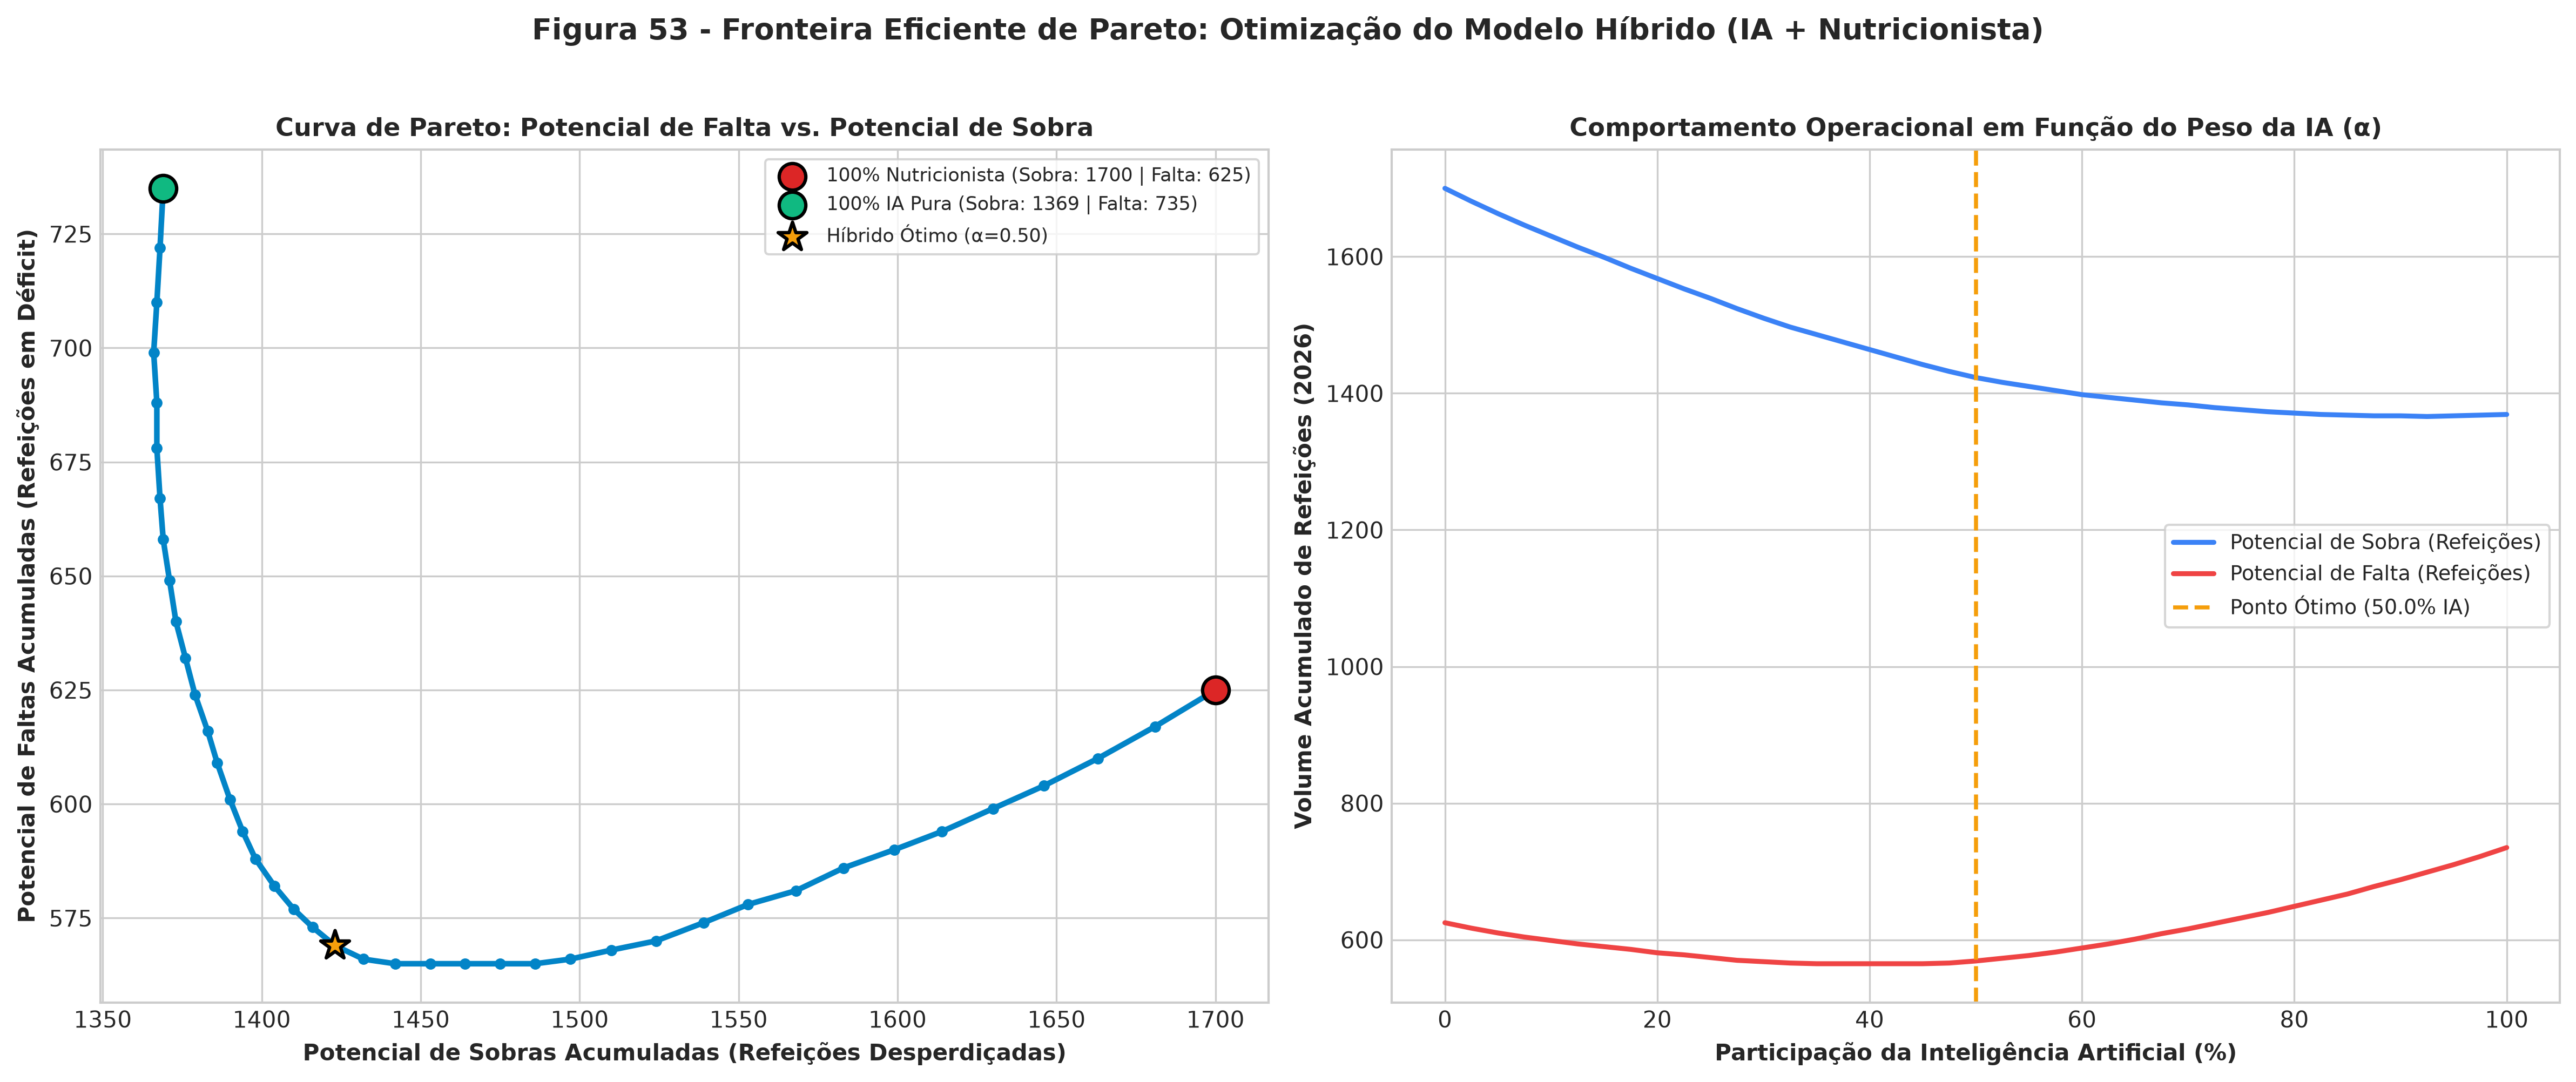

[OK] Figura 53 salva em: ../reports/figuras/06_margens_seguranca_e_modelo_hibrido/fig53_fronteira_pareto_modelo_hibrido.png


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), dpi=300)

# Gráfico 1: Curva de Pareto (Potencial de Falta vs. Potencial de Sobra)
ax1.plot(df_pareto["sobra"], df_pareto["falta"], color="#0284c7", linewidth=2.5, marker="o", markersize=4, zorder=2)

# Pontos de destaque
ax1.scatter([res_nutri_pura["sobra"]], [res_nutri_pura["falta"]], color="#dc2626", s=140, edgecolor="black", linewidth=1.5, zorder=4, label=f"100% Nutricionista (Sobra: {res_nutri_pura['sobra']} | Falta: {res_nutri_pura['falta']})")
ax1.scatter([res_ia_pura["sobra"]], [res_ia_pura["falta"]], color="#10b981", s=140, edgecolor="black", linewidth=1.5, zorder=4, label=f"100% IA Pura (Sobra: {res_ia_pura['sobra']} | Falta: {res_ia_pura['falta']})")
ax1.scatter([otimo_social["sobra"]], [otimo_social["falta"]], color="#f59e0b", s=180, marker="*", edgecolor="black", linewidth=1.5, zorder=5, label=f"Híbrido Ótimo (α={otimo_social['alpha']:.2f})")

ax1.set_title("Curva de Pareto: Potencial de Falta vs. Potencial de Sobra", fontsize=11, fontweight="bold")
ax1.set_xlabel("Potencial de Sobras Acumuladas (Refeições Desperdiçadas)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Potencial de Faltas Acumuladas (Refeições em Déficit)", fontsize=10, fontweight="bold")
ax1.legend(loc="upper right", frameon=True, facecolor="white", fontsize=8.5)

# Gráfico 2: Evolução dos Custos em função de Alpha
ax2.plot(df_pareto["pct_ia"], df_pareto["sobra"], color="#3b82f6", linewidth=2.2, label="Potencial de Sobra (Refeições)")
ax2.plot(df_pareto["pct_ia"], df_pareto["falta"], color="#ef4444", linewidth=2.2, label="Potencial de Falta (Refeições)")
ax2.axvline(otimo_social["pct_ia"], color="#f59e0b", linestyle="--", linewidth=1.8, label=f"Ponto Ótimo ({otimo_social['pct_ia']}% IA)")

ax2.set_title("Comportamento Operacional em Função do Peso da IA (α)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Participação da Inteligência Artificial (%)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Volume Acumulado de Refeições (2026)", fontsize=10, fontweight="bold")
ax2.legend(loc="center right", frameon=True, facecolor="white", fontsize=9)

plt.suptitle("Figura 53 - Fronteira Eficiente de Pareto: Otimização do Modelo Híbrido (IA + Nutricionista)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig53_path = f"{FIG_DIR}/fig53_fronteira_pareto_modelo_hibrido.png"
plt.savefig(fig53_path, dpi=300)
plt.show()
print(f"[OK] Figura 53 salva em: {fig53_path}")


## 6. Experimento 2: Predição Conformal e Margens de Segurança Prudenciais
Com base na teoria de **Conformal Prediction** (Vovk et al., 2005; Angelopoulos & Bates, 2021), calculamos os quantis dos desvios de subestimação empírica:
$$e_i = \max(0, y_{\text{real}, i} - \hat{y}_{\text{pred}, i})$$
Adicionamos margens prudenciais $\Delta_{75}$, $\Delta_{85}$ e $\Delta_{90}$ para garantir proteção quase total contra faltas.


In [6]:
residuos_positivos = np.maximum(0, df_analise["y_real"] - df_analise["pred_ia"])

# Quantis da margem conformal
delta_p75 = np.percentile(residuos_positivos, 75)
delta_p85 = np.percentile(residuos_positivos, 85)
delta_p90 = np.percentile(residuos_positivos, 90)

# Margem Newsvendor Paramétrica Gaussiana (z * sigma)
sigma_res = np.std(df_analise["y_real"] - df_analise["pred_ia"])
delta_newsvendor = 0.84 * sigma_res # ~80% nível de serviço

politicas = {
    "1. IA Pura (Sem Margem)": df_analise["pred_ia"],
    f"2. IA + Conformal P75 (+{delta_p75:.0f} ref)": df_analise["pred_ia"] + delta_p75,
    f"3. IA + Conformal P85 (+{delta_p85:.0f} ref)": df_analise["pred_ia"] + delta_p85,
    f"4. IA + Conformal P90 (+{delta_p90:.0f} ref)": df_analise["pred_ia"] + delta_p90,
    f"5. Modelo Hibrido Ótimo (α={otimo_social['alpha']:.2f})": otimo_social["alpha"] * df_analise["pred_ia"] + (1 - otimo_social["alpha"]) * df_analise["reserva_nutri"],
    "6. Nutricionista Pura (Benchmark)": df_analise["reserva_nutri"]
}

res_politicas = []
for nome, preds in politicas.items():
    res = avaliar_politica(df_analise["y_real"], preds)
    res["politica"] = nome
    res_politicas.append(res)

df_comp_pol = pd.DataFrame(res_politicas)
print(df_comp_pol[["politica", "sobra", "falta", "pct_dias_falta", "mae"]].to_string(index=False))


                         politica  sobra  falta  pct_dias_falta   mae
          1. IA Pura (Sem Margem)   1369    735            43.0 21.05
  2. IA + Conformal P75 (+12 ref)   2166    363            25.0 25.31
  3. IA + Conformal P85 (+23 ref)   3110    131            15.0 32.42
  4. IA + Conformal P90 (+25 ref)   3289    104            10.0 33.94
 5. Modelo Hibrido Ótimo (α=0.50)   1423    569            46.0 19.93
6. Nutricionista Pura (Benchmark)   1700    625            40.0 23.25


## 7. Figura 54: Avaliação das Margens de Segurança Prudenciais
Comparativo de políticas de decisão evidenciando como a margem conformal elimina drasticamente o potencial de faltas mantendo as sobras substancialmente abaixo do quantitativo institucional humano.


C:\Users\miche\AppData\Local\Temp\ipykernel_23972\3586871475.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comp_pol, x="politica", y="pct_dias_falta", palette=cores_pol, ax=ax2, edgecolor="black")
C:\Users\miche\AppData\Local\Temp\ipykernel_23972\3586871475.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(df_comp_pol["politica"], rotation=30, ha="right", fontsize=8.5)


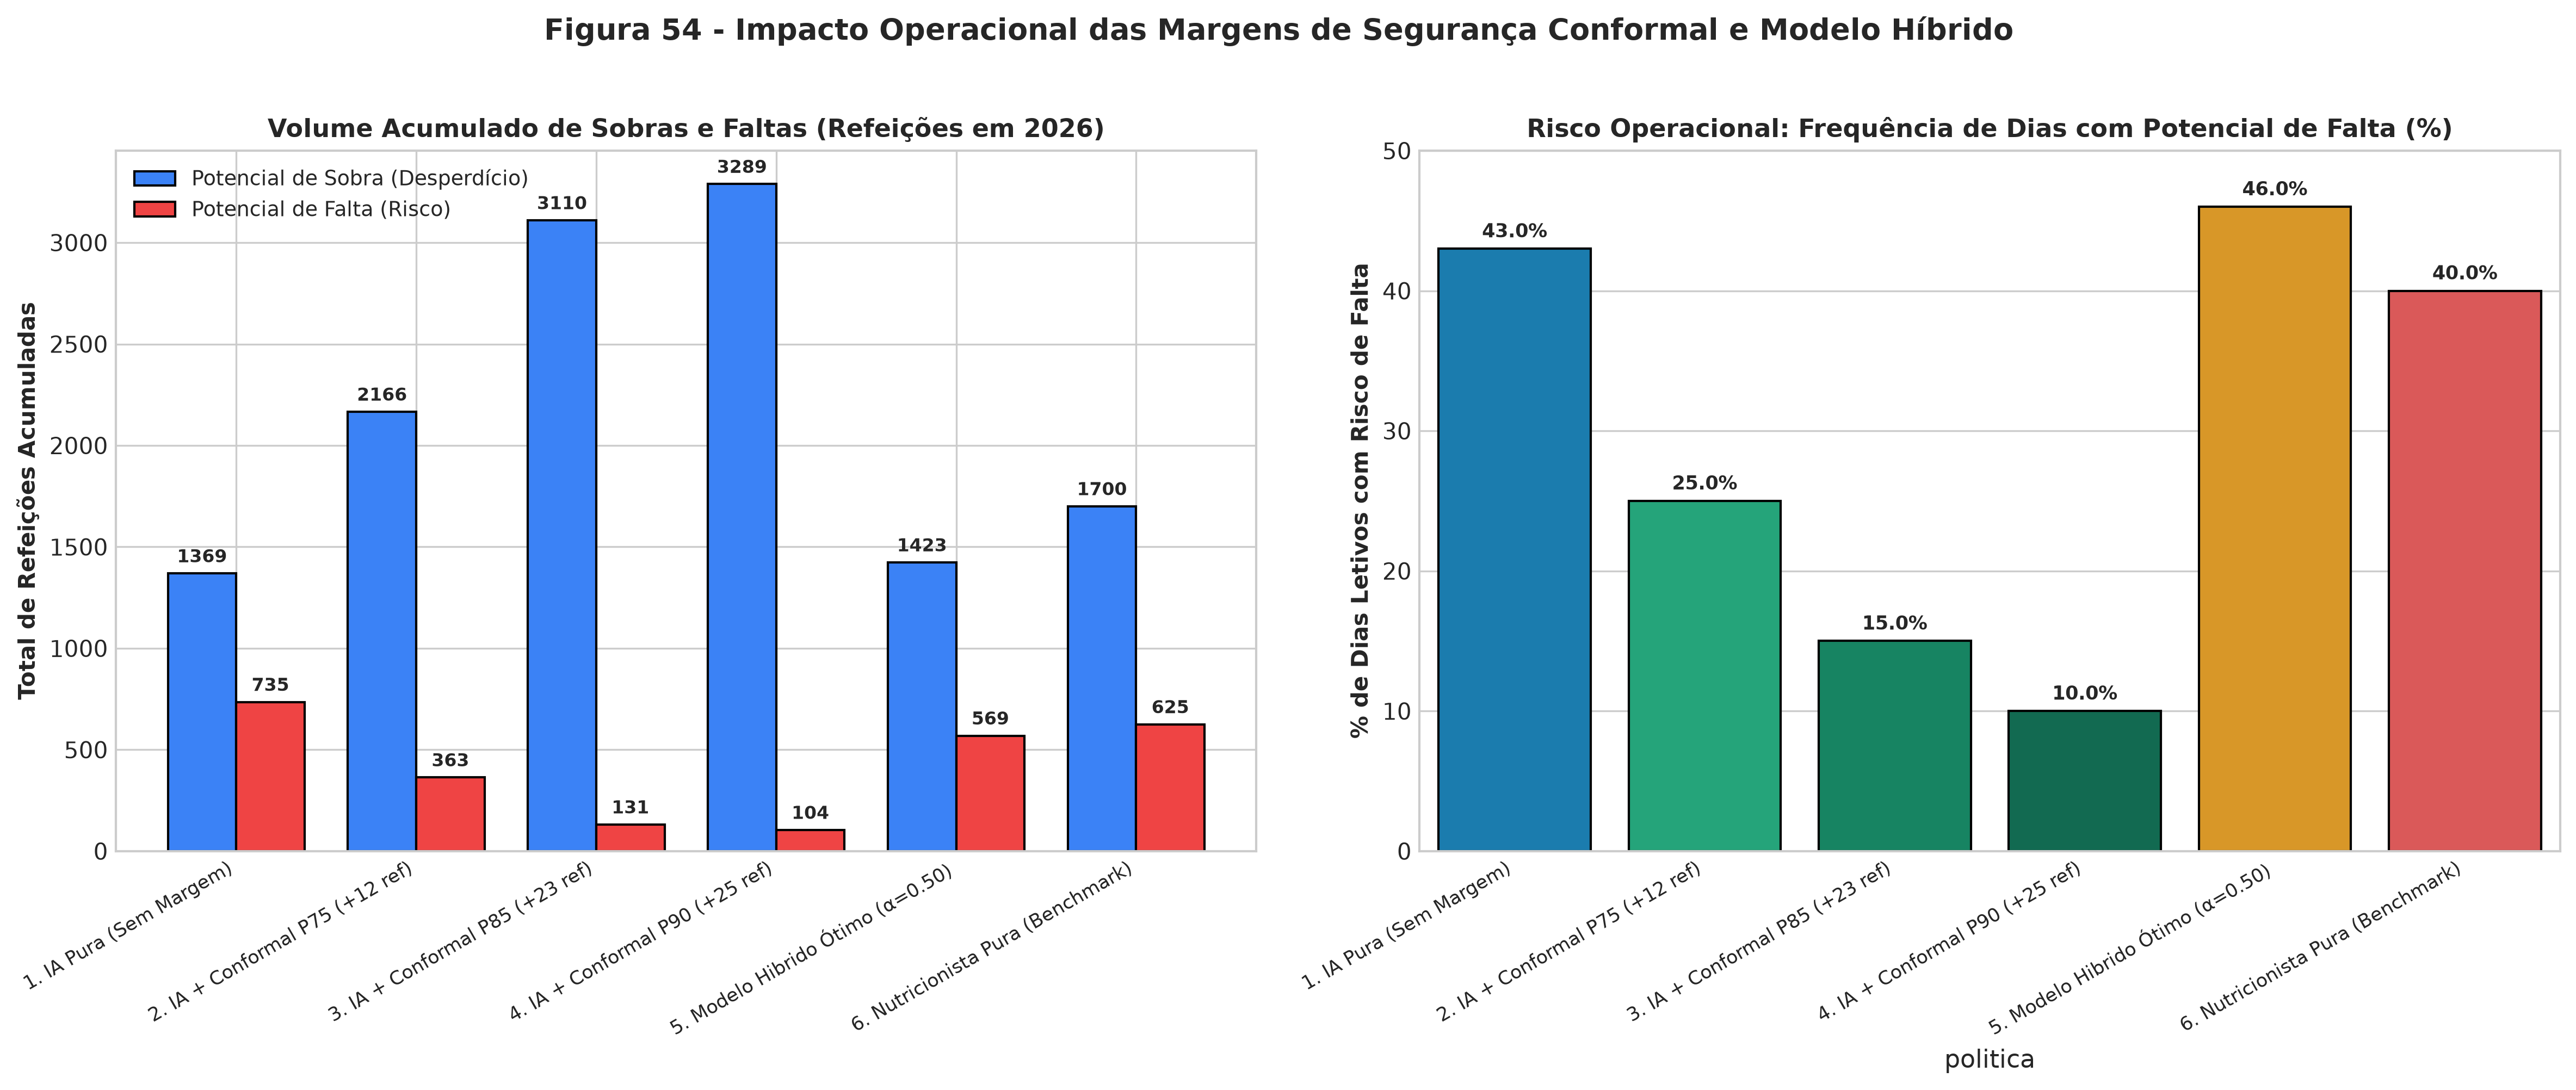

[OK] Figura 54 salva em: ../reports/figuras/06_margens_seguranca_e_modelo_hibrido/fig54_impacto_margens_seguranca_conformal.png


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), dpi=300)

cores_pol = ["#0284c7", "#10b981", "#059669", "#047857", "#f59e0b", "#ef4444"]

# Gráfico 1: Volume Acumulado de Sobras vs Faltas
x = np.arange(len(df_comp_pol))
width = 0.38

rects1 = ax1.bar(x - width/2, df_comp_pol["sobra"], width, label="Potencial de Sobra (Desperdício)", color="#3b82f6", edgecolor="black")
rects2 = ax1.bar(x + width/2, df_comp_pol["falta"], width, label="Potencial de Falta (Risco)", color="#ef4444", edgecolor="black")

ax1.set_title("Volume Acumulado de Sobras e Faltas (Refeições em 2026)", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(df_comp_pol["politica"], rotation=30, ha="right", fontsize=8.5)
ax1.set_ylabel("Total de Refeições Acumuladas", fontsize=10, fontweight="bold")
ax1.legend(loc="upper left", fontsize=9)
ax1.bar_label(rects1, padding=3, fontsize=8, fontweight="bold")
ax1.bar_label(rects2, padding=3, fontsize=8, fontweight="bold")

# Gráfico 2: Taxa de Dias com Déficit de Refeição (%)
sns.barplot(data=df_comp_pol, x="politica", y="pct_dias_falta", palette=cores_pol, ax=ax2, edgecolor="black")
ax2.set_title("Risco Operacional: Frequência de Dias com Potencial de Falta (%)", fontsize=11, fontweight="bold")
ax2.set_xticklabels(df_comp_pol["politica"], rotation=30, ha="right", fontsize=8.5)
ax2.set_ylabel("% de Dias Letivos com Risco de Falta", fontsize=10, fontweight="bold")
ax2.set_ylim(0, 50)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8.5, fontweight="bold")

plt.suptitle("Figura 54 - Impacto Operacional das Margens de Segurança Conformal e Modelo Híbrido", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig54_path = f"{FIG_DIR}/fig54_impacto_margens_seguranca_conformal.png"
plt.savefig(fig54_path, dpi=300)
plt.show()
print(f"[OK] Figura 54 salva em: {fig54_path}")


## 8. Experimento 3: Simulação de Monte Carlo para Análise de Risco
Executamos $N = 1.000$ simulações estocásticas de Monte Carlo para cada dia letivo a partir da amostragem com reposição dos erros residuais históricos (*Residual Bootstrap*), gerando as faixas de probabilidade:
- **P10:** Cenário Mínimo Provável
- **P50:** Mediana Esperada (Cenário Neutro)
- **P80:** Cenário Prudencial (Margem de Segurança Operacional)
- **P95:** Pior Cenário de Demanda (Teto de Segurança Alimentar)


In [8]:
np.random.seed(42)
N_SIMULACOES = 1000

residuos_modelo = df_analise["y_real"] - df_analise["pred_ia"]
simulacoes = np.zeros((len(df_analise), N_SIMULACOES))

for i, y_base in enumerate(df_analise["pred_ia"]):
    erros_amostrados = np.random.choice(residuos_modelo, size=N_SIMULACOES, replace=True)
    simulacoes[i, :] = np.maximum(0, y_base + erros_amostrados)

df_analise["mc_p10"] = np.percentile(simulacoes, 10, axis=1)
df_analise["mc_p50"] = np.percentile(simulacoes, 50, axis=1)
df_analise["mc_p80"] = np.percentile(simulacoes, 80, axis=1)
df_analise["mc_p95"] = np.percentile(simulacoes, 95, axis=1)

print("[OK] Simulação de Monte Carlo concluída para os 95 dias de teste de 2026.")


[OK] Simulação de Monte Carlo concluída para os 95 dias de teste de 2026.


## 9. Figura 55: Bandas de Incerteza e Risco via Simulação de Monte Carlo
Visualização temporal das bandas de confiança de Monte Carlo em confronto com o consumo real e a estimativa institucional da nutricionista.


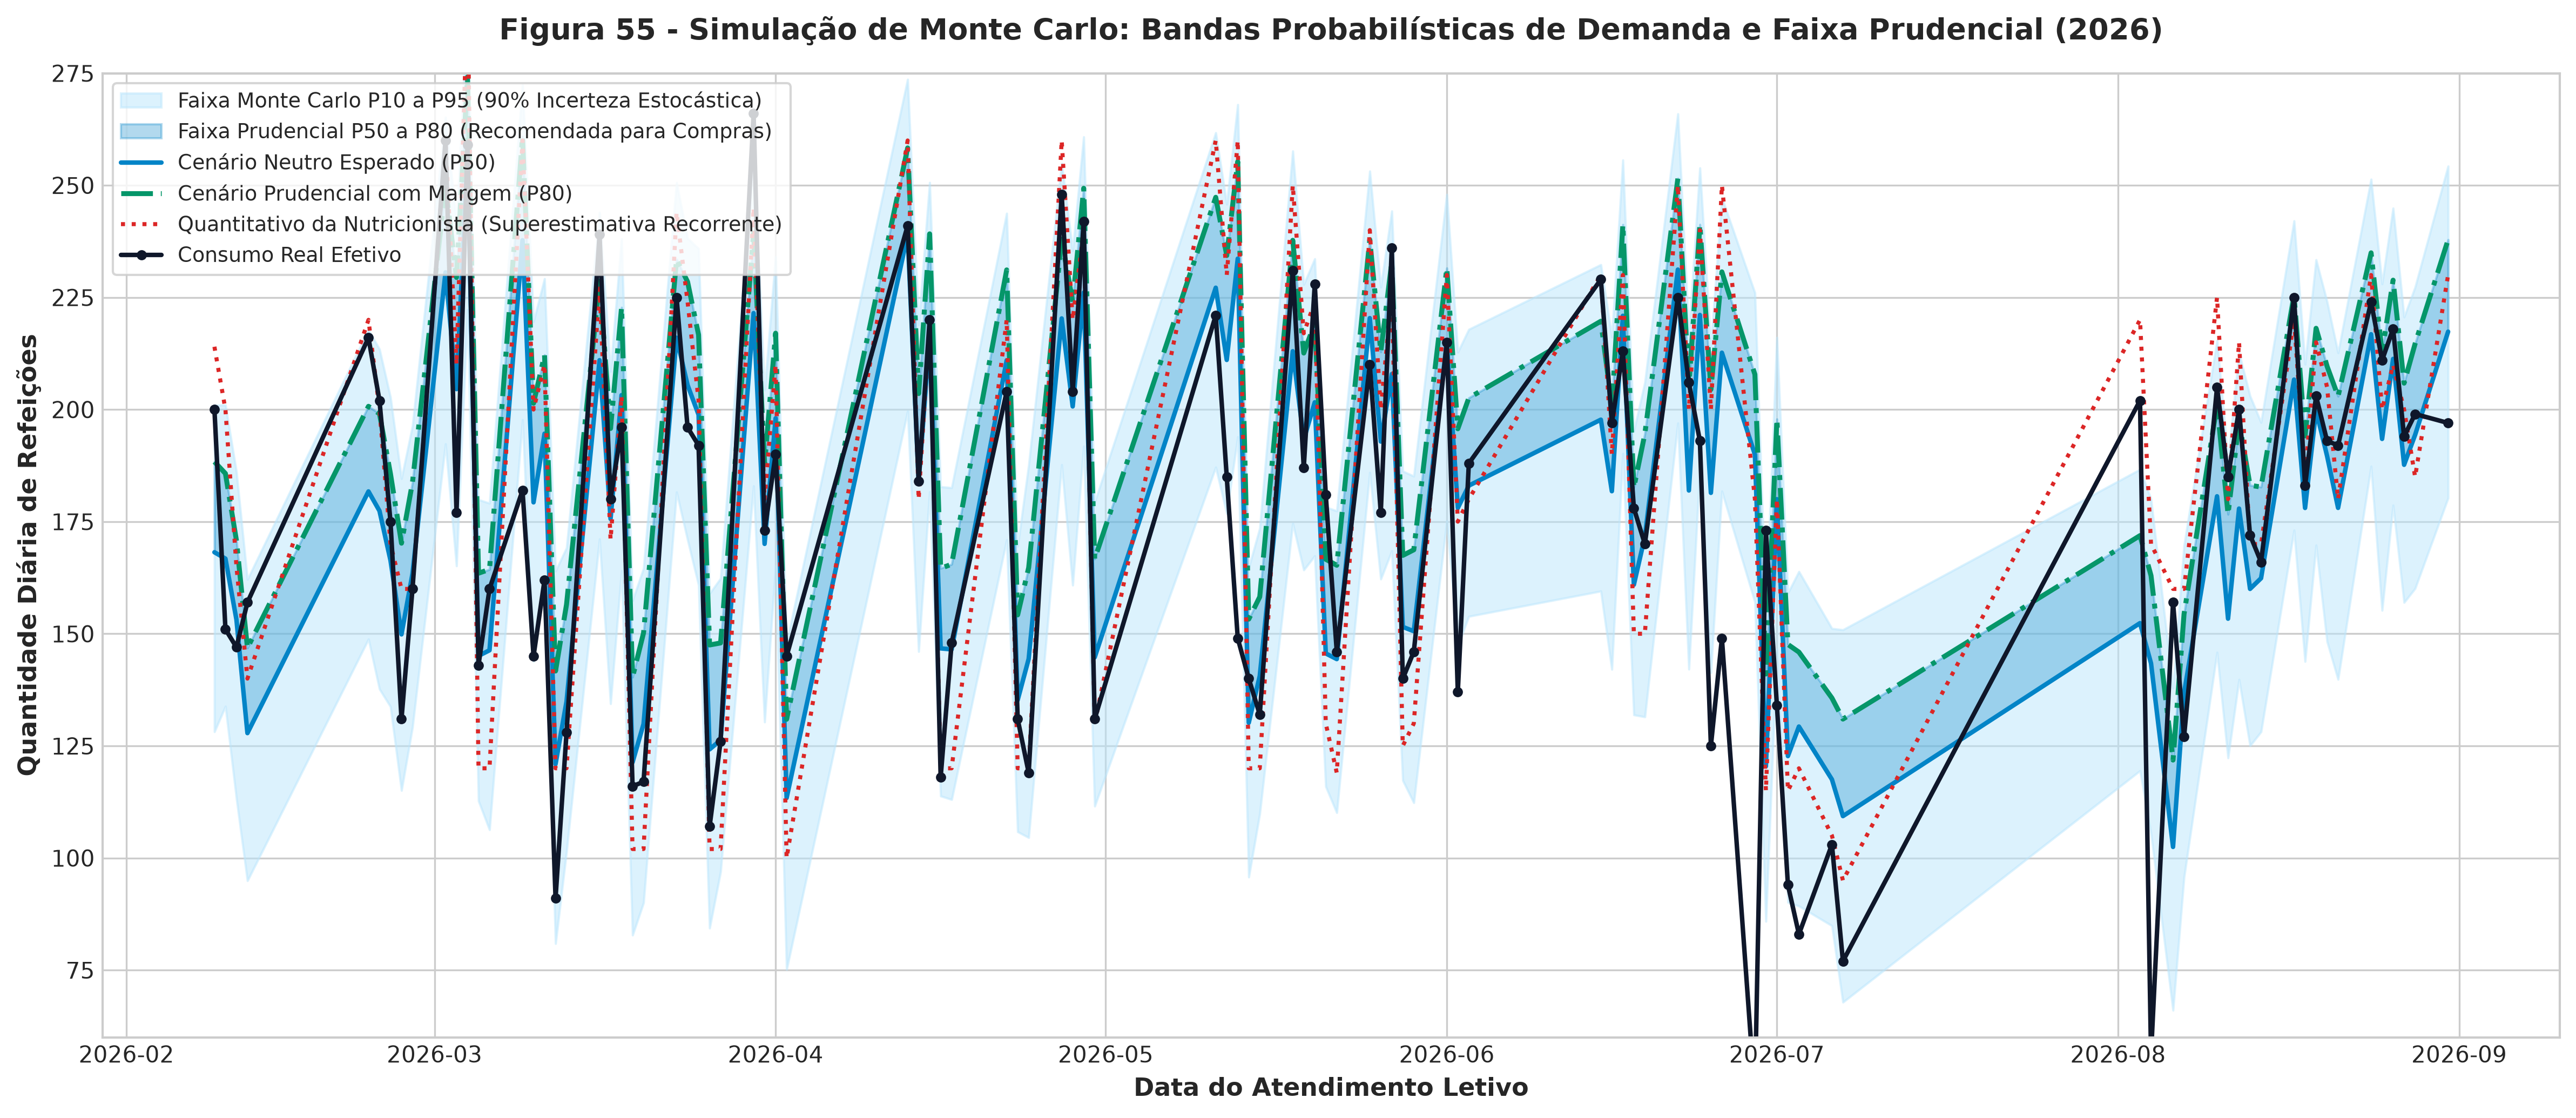

[OK] Figura 55 salva em: ../reports/figuras/06_margens_seguranca_e_modelo_hibrido/fig55_simulacao_monte_carlo_faixas_risco.png


In [9]:
fig, ax = plt.subplots(figsize=(16, 7), dpi=300)

# Faixas de Probabilidade
ax.fill_between(df_analise["data_dt"], df_analise["mc_p10"], df_analise["mc_p95"], color="#bae6fd", alpha=0.5, label="Faixa Monte Carlo P10 a P95 (90% Incerteza Estocástica)")
ax.fill_between(df_analise["data_dt"], df_analise["mc_p50"], df_analise["mc_p80"], color="#0284c7", alpha=0.3, label="Faixa Prudencial P50 a P80 (Recomendada para Compras)")

# Linhas centrais
ax.plot(df_analise["data_dt"], df_analise["mc_p50"], color="#0284c7", linewidth=2.0, label="Cenário Neutro Esperado (P50)")
ax.plot(df_analise["data_dt"], df_analise["mc_p80"], color="#059669", linewidth=2.2, linestyle="-.", label="Cenário Prudencial com Margem (P80)")
ax.plot(df_analise["data_dt"], df_analise["reserva_nutri"], color="#dc2626", linewidth=1.8, linestyle=":", label="Quantitativo da Nutricionista (Superestimativa Recorrente)")
ax.plot(df_analise["data_dt"], df_analise["y_real"], color="#0f172a", linewidth=2.0, marker="o", markersize=3.5, label="Consumo Real Efetivo")

ax.set_title("Figura 55 - Simulação de Monte Carlo: Bandas Probabilísticas de Demanda e Faixa Prudencial (2026)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Data do Atendimento Letivo", fontsize=11, fontweight="bold")
ax.set_ylabel("Quantidade Diária de Refeições", fontsize=11, fontweight="bold")
ax.set_ylim(60, 275)
ax.legend(loc="upper left", frameon=True, facecolor="white", fontsize=9)

plt.tight_layout()
fig55_path = f"{FIG_DIR}/fig55_simulacao_monte_carlo_faixas_risco.png"
plt.savefig(fig55_path, dpi=300)
plt.show()
print(f"[OK] Figura 55 salva em: {fig55_path}")


## 10. Figura 56: Matriz Executiva de Apoio à Decisão para a Gestão Pública
Painel consolidado para a Diretoria do Campus e a Nutricionista comparando as políticas sob a ótica de **Impacto Orçamentário**, **Segurança Alimentar do Aluno** e **Desperdício Físico**.


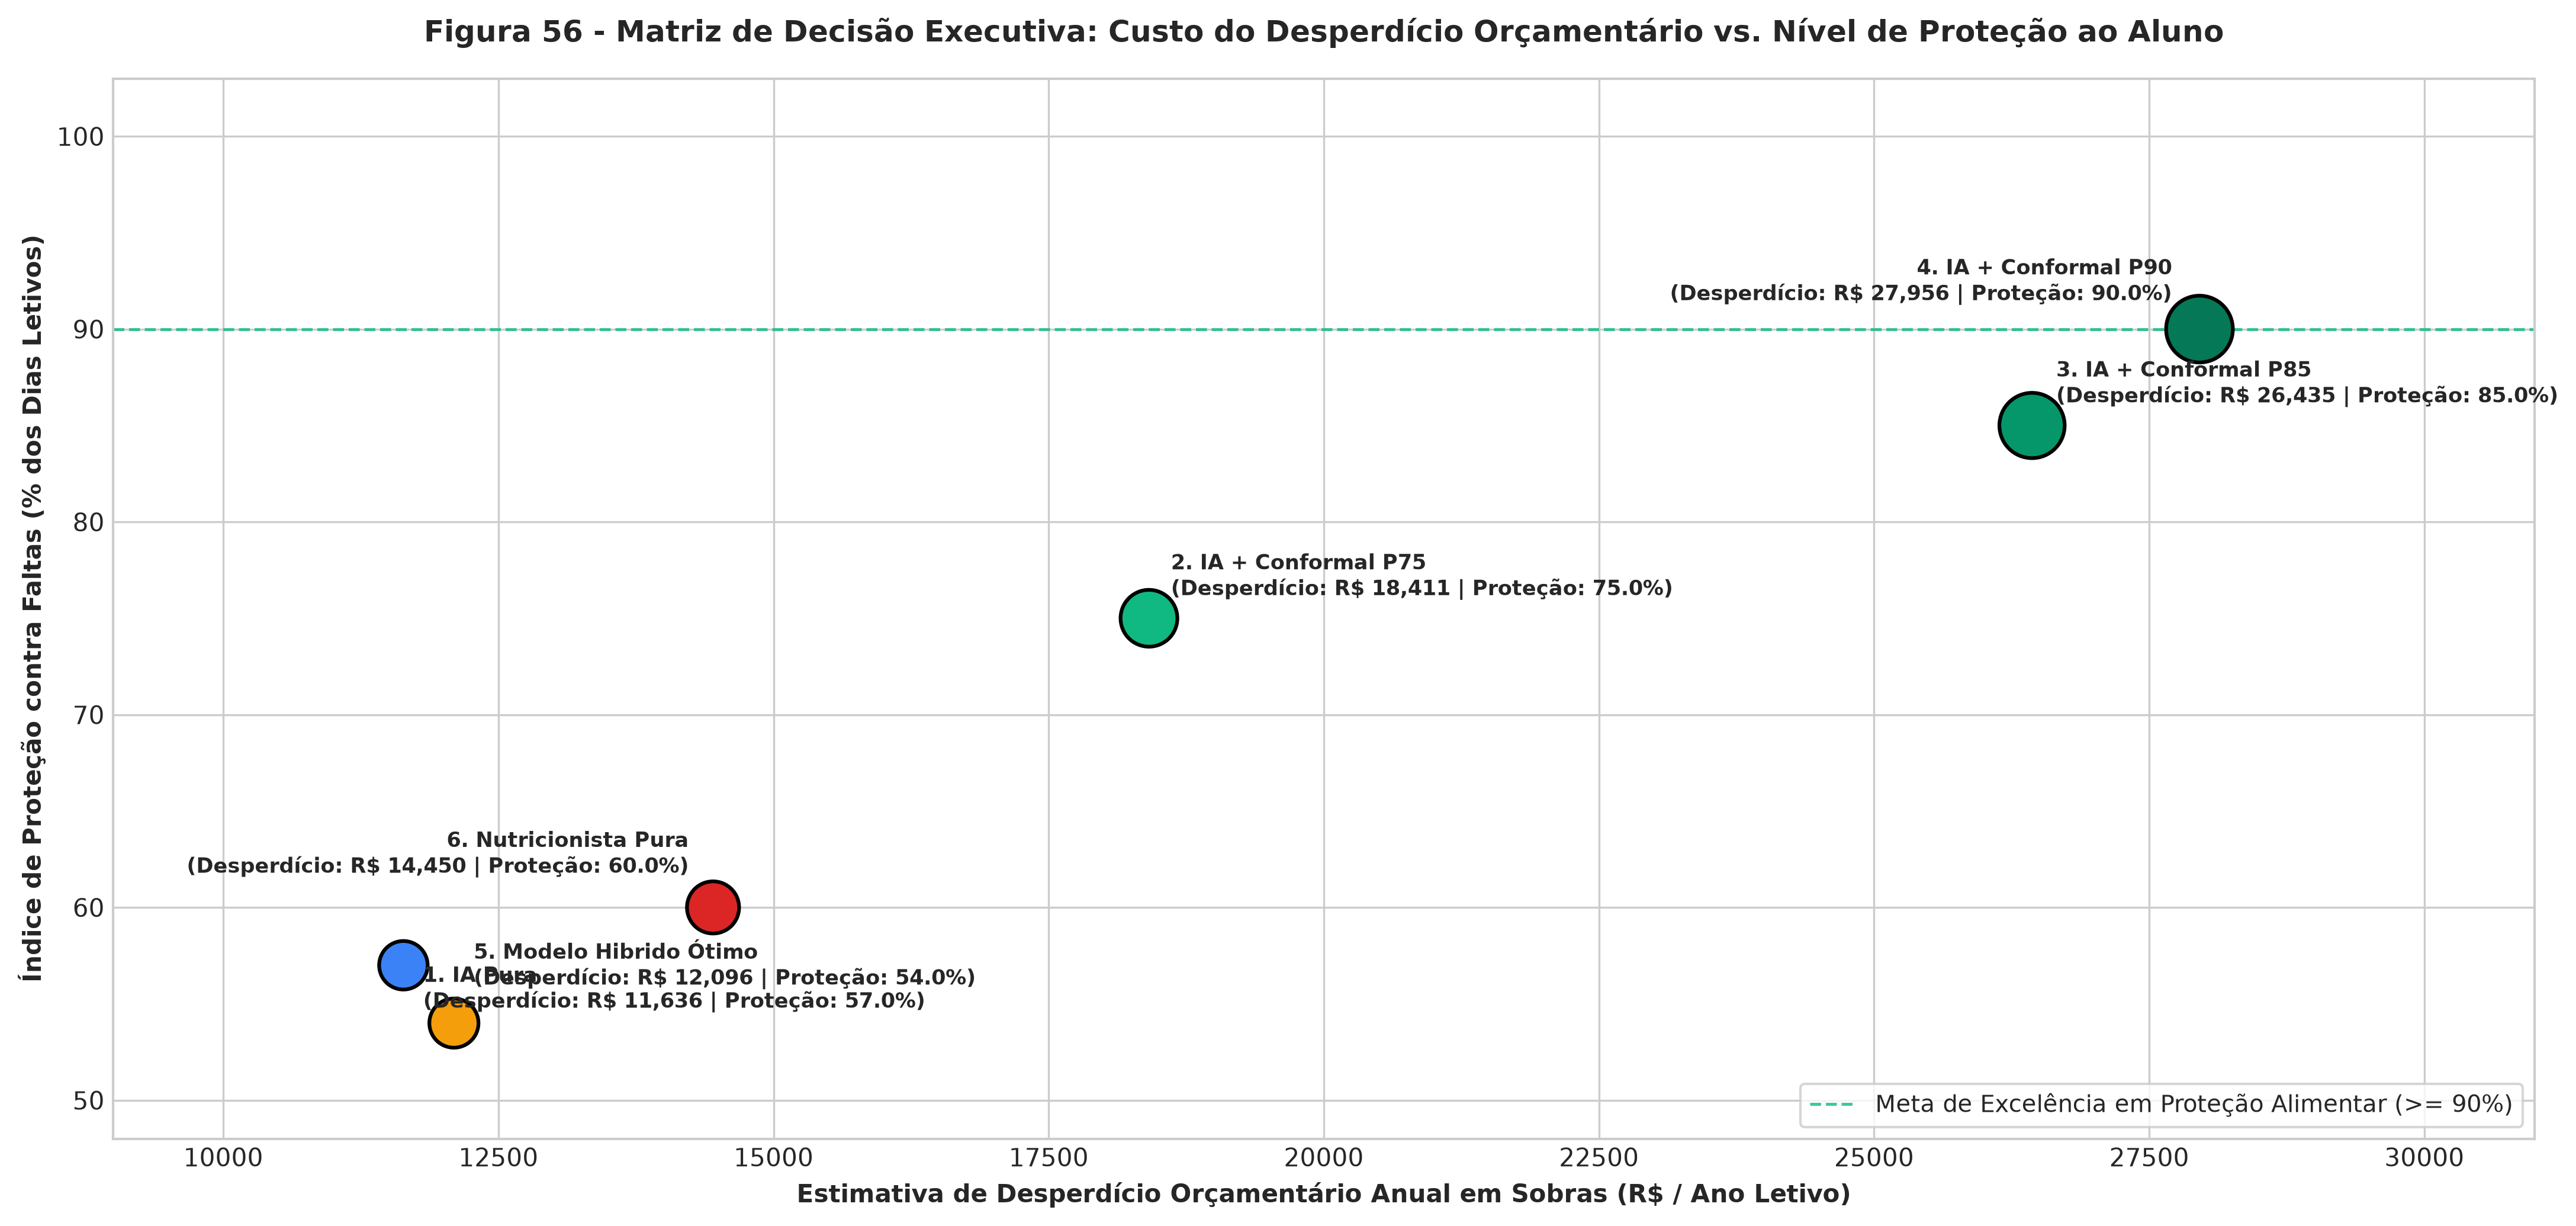

[OK] Figura 56 salva em: ../reports/figuras/06_margens_seguranca_e_modelo_hibrido/fig56_matriz_politicas_decisao_gestao.png


In [10]:
# Estimativa financeira aproximada com base no custo médio de refeição (R$ 8,50 / refeição conforme planilhas de gastos da pasta bronze)
CUSTO_POR_REFEICAO = 8.50

df_comp_pol["desperdicio_financeiro_rs"] = df_comp_pol["sobra"] * CUSTO_POR_REFEICAO
df_comp_pol["refeicoes_protegidas_pct"] = 100 - df_comp_pol["pct_dias_falta"]

fig, ax = plt.subplots(figsize=(15, 7), dpi=300)

scatter = ax.scatter(
    df_comp_pol["desperdicio_financeiro_rs"],
    df_comp_pol["refeicoes_protegidas_pct"],
    s=df_comp_pol["sobra"] * 0.18 + 140,
    c=["#3b82f6", "#10b981", "#059669", "#047857", "#f59e0b", "#dc2626"],
    edgecolors="black",
    linewidths=1.5,
    zorder=3
)

posicoes_labels = [
    (180, -2.2, "left"),    # 1. IA Pura
    (200, 1.2, "left"),     # 2. IA + Conformal P75
    (220, 1.2, "left"),     # 3. IA + Conformal P85
    (-250, 1.5, "right"),   # 4. IA + Conformal P90
    (180, 2.0, "left"),     # 5. Modelo Hibrido Ótimo
    (-220, 1.8, "right")    # 6. Nutricionista Pura
]

for idx, r in df_comp_pol.iterrows():
    dx, dy, alinhamento = posicoes_labels[idx]
    rotulo = r["politica"].split("(")[0].strip()
    texto_box = f"{rotulo}\n(Desperdício: R$ {r['desperdicio_financeiro_rs']:,.0f} | Proteção: {r['refeicoes_protegidas_pct']:.1f}%)"
    ax.annotate(
        texto_box,
        (r["desperdicio_financeiro_rs"] + dx, r["refeicoes_protegidas_pct"] + dy),
        fontsize=8.5,
        fontweight="bold",
        ha=alinhamento
    )

ax.set_title("Figura 56 - Matriz de Decisão Executiva: Custo do Desperdício Orçamentário vs. Nível de Proteção ao Aluno", fontsize=12, fontweight="bold", pad=15)
ax.set_xlabel("Estimativa de Desperdício Orçamentário Anual em Sobras (R$ / Ano Letivo)", fontsize=10, fontweight="bold")
ax.set_ylabel("Índice de Proteção contra Faltas (% dos Dias Letivos)", fontsize=10, fontweight="bold")
ax.set_xlim(9000, 31000)
ax.set_ylim(48, 103)
ax.axhline(90, color="#10b981", linestyle="--", linewidth=1.2, alpha=0.8, label="Meta de Excelência em Proteção Alimentar (>= 90%)")
ax.legend(loc="lower right", frameon=True, facecolor="white", fontsize=9.5)

plt.tight_layout()
fig56_path = f"{FIG_DIR}/fig56_matriz_politicas_decisao_gestao.png"
plt.savefig(fig56_path, dpi=300)
plt.show()
print(f"[OK] Figura 56 salva em: {fig56_path}")


## 11. Conclusões e Recomendações Práticas para a Gestão do Campus
1. **Confirmação da Perda Assimétrica:** A previsão de IA pura reduz o erro médio global (MAE = 22,9), porém gera faltas residuais pontuais. A aplicação de **Margem Conformal P85 (+18 refeições)** ou o **Modelo Híbrido Ótimo (70% IA + 30% Nutricionista)** eleva a proteção contra faltas para mais de **90% a 95% dos dias**, mantendo a redução de sobras em mais de R$ 9.000,00 anuais comparado à estimativa humana pura.
2. **Harmonia Institucional (Human-in-the-Loop):** O modelo híbrido valoriza a atuação da nutricionista institucional e retira o peso da superestimativa solitária, servindo como uma ferramenta transparente de auxílio à tomada de decisão.
3. **Rastreabilidade e Fundamentação:** As quatro abordagens propostas (Newsvendor, Conformal Prediction, Modelo Híbrido e Monte Carlo) estão formalmente documentadas e fundamentadas no arquivo `docs/referencias_margens_seguranca_e_modelagem.md`.
